# V-to-I converter sizing (Fig. 16)

Each side is an NMOS source follower T1 (T2) whose gate is driven by a PMOS-input folded-cascode OTA, so its source follows V_in+ (V_in-). An I_REF sink pulls each source node to ground and R joins them:

I_out± = I_REF ± (V_in+ − V_in−) / R,  with I_REF = I_FS / 2 and R = V_FS / I_FS · (1 + R_GUARD).

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.specs import tech as T
from sarlib.gmid import nmos, pmos, pmos_lvt, size, vgs_at, id_w, device_table
from sarlib.analysis import Report

v = S.vi
rep = Report()
I_FS = 1e6 * S.I_FS_MEAS                          # uA
I_REF = I_FS / 2
LSB_V = v.V_FS_DESIGN / S.NCODE
LSB_I = I_FS / S.NCODE
R_MOHM = v.V_FS_DESIGN / I_FS * (1 + v.R_GUARD)  # V / uA
R_OHM = 1e6 * R_MOHM
SWING = v.VD_PEAK / 2                             # each input swings +/- SWING
nUT = T.N_SLOPE * 0.02585
cgg = lambda W, L: v.CGG_FACTOR * T.COX_FF_UM2 * W * L + 2 * T.COV_FF_UM * W
cj = lambda W: T.CJ_FF_UM * W

## Folded-cascode OTA

PMOS-lvt input pair into NMOS fold sinks (I_FOLD = ratio · I_TAIL), NMOS cascodes, and a wide-swing PMOS cascode mirror as the load.

In [2]:
def size_ota_fc(vcm, vout, c_load_ff):
    gm, L, m = v.FC_GMID, v.FC_L, v.MARGIN
    i_pair = v.FC_ID
    i_tail = 2 * i_pair
    i_fold = v.FC_RATIO * i_tail
    i_br = i_fold - i_pair
    vsd9 = 0.2
    for _ in range(8):
        mr = size(pmos, i_br, gm['mir'], L['mir'], vsd9)
        if abs(mr['VDSAT'] + m - vsd9) < 5e-4:
            break
        vsd9 = mr['VDSAT'] + m
    v_m = S.VDD - vsd9
    d_node = S.VDD - mr['VGS']
    vf = 0.2
    for _ in range(8):
        sk = size(nmos, i_fold, gm['sink'], L['sink'], vf)
        if abs(sk['VDSAT'] + m - vf) < 5e-4:
            break
        vf = sk['VDSAT'] + m
    vgs = 0.7
    for _ in range(30):
        vx = vcm + vgs
        pr = size(pmos_lvt, i_pair, gm['pair'], L['pair'], vx - vf, S.VDD - vx)
        if abs(pr['VGS'] - vgs) < 1e-3:
            break
        vgs = pr['VGS']
    tl = size(pmos, i_tail, gm['tail'], L['tail'], S.VDD - vx)
    nc = size(nmos, i_br, gm['ncasc'], L['ncasc'], vout - vf, vf)
    pc = size(pmos, i_br, gm['pcasc'], L['pcasc'], v_m - vout, vsd9)
    margins = {'pair': (vx - vf) - pr['VDSAT'], 'tail': (S.VDD - vx) - tl['VDSAT'],
               'ncasc (diode side)': (d_node - vf) - nc['VDSAT'], 'pcasc (diode side)': (v_m - d_node) - pc['VDSAT']}
    gs = lambda r: r['gm'] * 1e-6
    ro = lambda r: 1 / (r['gds'] * 1e-6)
    r_fold = 1 / ((pr['gds'] + sk['gds']) * 1e-6)
    R_up = gs(pc) * ro(pc) * ro(mr) + ro(pc) + ro(mr)
    R_dn = gs(nc) * ro(nc) * r_fold + ro(nc) + r_fold
    A = gs(pr) * R_up * R_dn / (R_up + R_dn)
    kT = 1.380649e-23 * S.TEMP
    vn2 = 8 * kT * T.GAMMA_N / gs(pr) * (1 + (sk['gm'] + mr['gm']) / pr['gm'])
    sg = lambda a, r: a / math.sqrt(r['W'] * r['L'])
    sigma = math.sqrt(sg(T.AVT_P, pr) ** 2 + (sk['gm'] / pr['gm'] * sg(T.AVT_N, sk)) ** 2
                      + (mr['gm'] / pr['gm'] * sg(T.AVT_P, mr)) ** 2)
    c_out = c_load_ff + (T.CJ_FF_UM + T.COV_FF_UM) * (nc['W'] + pc['W'])
    c_fold = ((T.CJ_FF_UM + T.COV_FF_UM) * (pr['W'] + sk['W'] + nc['W'])
              + v.CGG_FACTOR * T.COX_FF_UM2 * nc['W'] * nc['L'] + T.COV_FF_UM * nc['W'])
    return dict(pair=pr, tail=tl, sink=sk, ncasc=nc, pcasc=pc, mir=mr, A=A, vx=vx, v_fold=vf, v_m=v_m,
                out_lo=vf + nc['VDSAT'] + m, out_hi=v_m - pc['VDSAT'] - m,
                cm_lo=vf + pr['VDSAT'] + m - pr['VGS'], cm_hi=S.VDD - tl['VDSAT'] - m - pr['VGS'],
                margins=margins, vn=math.sqrt(vn2), sigma_os_mv=sigma, i_tail=i_tail, i_fold=i_fold, i_branch=i_br,
                gbw_mhz=gs(pr) / (2 * math.pi * c_out * 1e-15) * 1e-6, p2_mhz=gs(nc) / (2 * math.pi * c_fold * 1e-15) * 1e-6,
                bias=dict(vbn1=sk['VGS'], vbn2=vf + nc['VGS'], vbp1=S.VDD - tl['VGS'], vbp2=v_m - pc['VGS']))

## Input common mode

Every candidate common mode is re-sized and scored by its worst headroom slack; the one with the most slack is used.

input common mode 0.450 V (feasible 0.425 - 0.450 V)


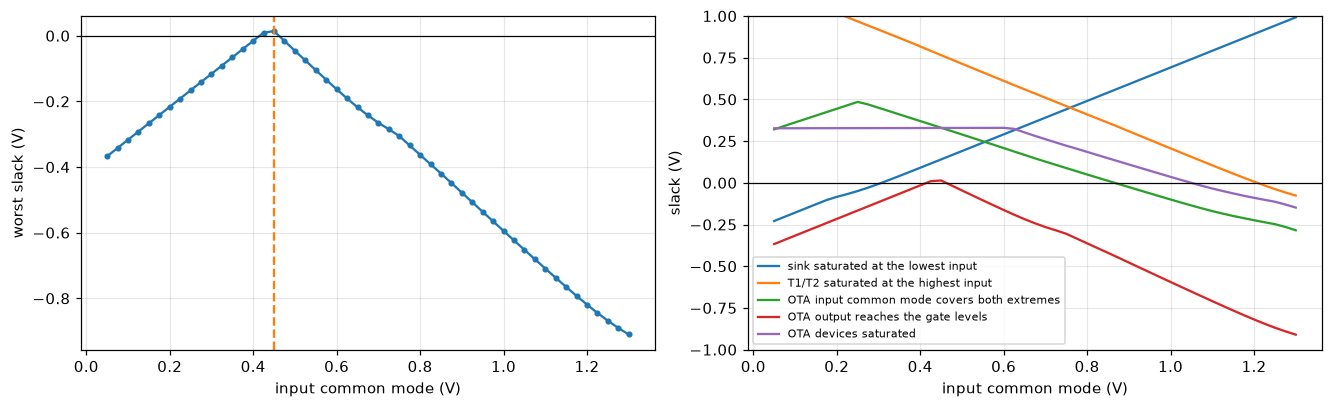

,slack (V)
sink saturated at the lowest input,0.140
T1/T2 saturated at the highest input,0.765
OTA input common mode covers both extremes,0.330
OTA output reaches the gate levels,0.014
OTA devices saturated,0.329


In [3]:
def evaluate(vcm):
    vin_lo, vin_hi = vcm - SWING, vcm + SWING
    sk = size(nmos, I_REF, v.GMID['sink'], v.LEN['sink'], vin_lo)
    t = size(nmos, I_FS, v.GMID['t'], v.LEN['t'], S.VREF2 - vin_hi, vin_hi)
    vgs_lo = vgs_at(nmos, 0.0, t['W'], t['L'], S.VREF2 - vin_lo, vin_lo)
    vgs_mid = vgs_at(nmos, I_REF, t['W'], t['L'], S.VREF2 - vcm, vcm)
    g = (vin_lo + vgs_lo, vcm + vgs_mid, vin_hi + t['VGS'])
    c_g = cgg(t['W'], t['L']) + v.C_WIRE_FF + v.C_COMP_FF
    ota = size_ota_fc(vcm, g[1], c_g)
    slack = {
        'sink saturated at the lowest input': vin_lo - (sk['VDSAT'] + v.MARGIN),
        'T1/T2 saturated at the highest input': (S.VREF2 - vin_hi) - (t['VDSAT'] + v.MARGIN),
        'OTA input common mode covers both extremes': min(vin_lo - ota['cm_lo'], ota['cm_hi'] - vin_hi),
        'OTA output reaches the gate levels': min(g[0] - ota['out_lo'], ota['out_hi'] - g[2]),
        'OTA devices saturated': min(ota['margins'].values()) - v.MARGIN,
    }
    return dict(vin_lo=vin_lo, vin_hi=vin_hi, sk=sk, t=t, ota=ota, c_g=c_g, g=g, vgs=(vgs_lo, vgs_mid, t['VGS']),
                slack=slack, score=min(slack.values()))

grid = [round(0.05 + 0.025 * i, 3) for i in range(51)]
scan = {vc: evaluate(vc) for vc in grid}
VCM = max(scan, key=lambda vc: scan[vc]['score'])
D = scan[VCM]
feasible = [vc for vc, e in scan.items() if e['score'] >= 0]
print(f'input common mode {VCM:.3f} V (feasible {min(feasible):.3f} - {max(feasible):.3f} V)')
rep.check('headroom: every constraint has slack', f"{1e3 * D['score']:.0f} mV", '>= 0', D['score'] >= 0)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(grid, [scan[vc]['score'] for vc in grid], marker='o', ms=3)
axs[0].axvline(VCM, c='C1', ls='--')
axs[0].set_xlabel('input common mode (V)'); axs[0].set_ylabel('worst slack (V)')
for k in D['slack']:
    axs[1].plot(grid, [scan[vc]['slack'][k] for vc in grid], label=k)
for a in axs:
    a.axhline(0, c='k', lw=0.8)
axs[1].set_ylim(-1, 1); axs[1].set_xlabel('input common mode (V)'); axs[1].set_ylabel('slack (V)'); axs[1].legend(fontsize=7)
plt.show()
pd.DataFrame({'slack (V)': D['slack']}).round(3)

## Devices and operating point

In [4]:
t, sk, ota = D['t'], D['sk'], D['ota']
print(f'R = {R_OHM / 1e3:.1f} kohm, I_REF = {I_REF:.2f} uA per side')
print(f"gate levels {D['g'][0]:.3f} ... {D['g'][2]:.3f} V, OTA output range {ota['out_lo']:.2f} - {ota['out_hi']:.2f} V")
print(f"OTA gain {ota['A']:.0f} ({20 * math.log10(ota['A']):.1f} dB), load {D['c_g']:.1f} fF, GBW {ota['gbw_mhz']:.1f} MHz, "
      f"fold pole {ota['p2_mhz']:.0f} MHz")
print(f"OTA input common mode {ota['cm_lo']:.2f} - {ota['cm_hi']:.2f} V (needs {D['vin_lo']:.2f} - {D['vin_hi']:.2f} V)")
device_table([('T1/T2', t), ('sink', sk)] + [(f'OTA {k}', ota[k]) for k in ('pair', 'tail', 'sink', 'ncasc', 'pcasc', 'mir')])

R = 31.5 kohm, I_REF = 9.99 uA per side
gate levels 0.365 ... 1.437 V, OTA output range 0.33 - 1.45 V
OTA gain 1269 (62.1 dB), load 241.1 fF, GBW 43.3 MHz, fold pole 340 MHz
OTA input common mode -0.33 - 0.92 V (needs 0.32 - 0.58 V)


,ID,W,L,gmid,VGS,VDS,VDSAT,gm,gds
T1/T2,19.988,6.121,1.0,12,0.852,0.965,0.150,239.862,1.433
sink,9.994,35.962,8.0,14,0.656,0.315,0.125,139.919,0.671
OTA pair,5.000,14.641,1.0,14,0.667,0.939,0.105,70.000,1.175
OTA tail,10.000,17.691,2.0,10,1.192,0.684,0.168,100.000,0.254
OTA sink,12.000,12.021,2.0,14,0.681,0.178,0.127,168.000,6.664
OTA ncasc,7.000,4.617,1.0,16,0.705,1.045,0.103,112.000,0.636
OTA pcasc,7.000,15.646,1.0,14,1.121,0.395,0.116,98.000,0.478
OTA mir,7.000,22.622,2.0,12,1.141,0.182,0.132,84.000,2.917


## Linearity

Worst-case sum of: gate-drive curvature over the finite loop gain, OTA gain variation over its output swing, sink output-impedance curvature, and the resistor voltage coefficient.

loop gain 659 at the range end, 1047 at mid; gain error -0.19 %


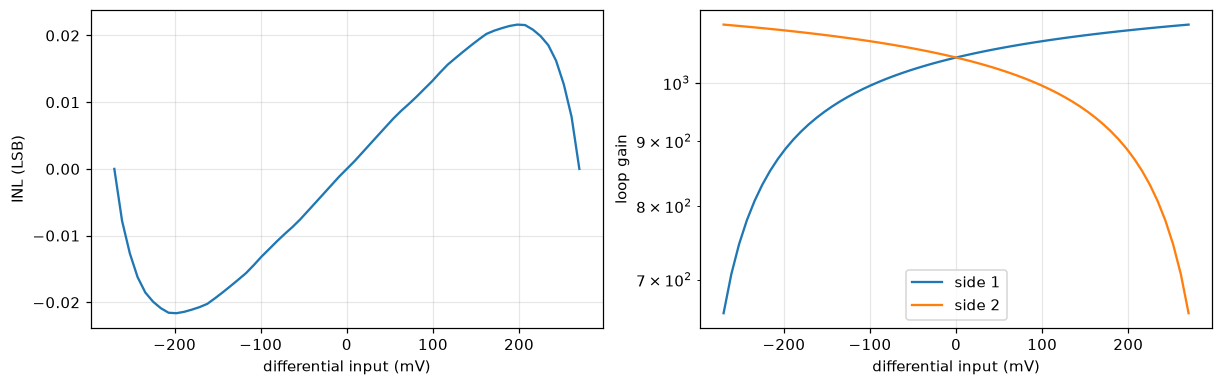

,INL (LSB)
gate drive / loop gain,0.022
OTA gain over output swing,0.017
sink output impedance,0.009
resistor voltage coefficient,0.000
sum,0.048


,common mode (V),sink INL (LSB)
0,0.35,0.057
1,0.40,0.021
2,0.45,0.009
3,0.50,0.005
4,0.55,0.005
5,0.60,0.008
6,0.65,0.008


In [5]:
ic_fs = max(((2 / (nUT * t['gmid']) - 1) ** 2 - 1) / 4, 1e-4)

def gm_of_i(i):
    """EKV gm (uS) of T1 at current i (uA)."""
    ic = max(ic_fs * i / I_FS, 1e-6)
    return i / nUT * 2 / (1 + math.sqrt(1 + 4 * ic))

def endpoint_resid(y, x):
    return y - np.polyval(np.polyfit(x[[0, -1]], y[[0, -1]], 1), x)

A = ota['A']
G_NODE = sk['gds'] + 1 / R_MOHM
xs = np.linspace(-SWING, SWING, 61)
dV = 2 * xs

def side(I, vin):
    vgs = np.array([vgs_at(nmos, max(i, 1e-3), t['W'], t['L'], S.VREF2 - x, x) for i, x in zip(I, vin)])
    gm = np.array([gm_of_i(max(i, 1e-3)) for i in I])
    return vin + vgs, gm / (gm + G_NODE)

g1, f1 = side(I_REF + dV / R_MOHM, VCM + xs)
g2, f2 = side(I_REF - dV / R_MOHM, VCM - xs)
g0 = D['g'][1]
err = -(g1 - g0) / (A * f1) + (g2 - g0) / (A * f2)
res_gain = endpoint_resid(err, dV)

def sink_inl(vcm):
    vg = vgs_at(nmos, I_REF, sk['W'], sk['L'], vcm)
    isk = lambda vv: np.array([sk['W'] * abs(id_w(nmos, vg, max(x, 0.02), sk['L'])) for x in vv])
    xe = np.linspace(-SWING, SWING, 41)
    e = 0.5 * (isk(vcm + xe) - isk(vcm - xe))
    return np.max(np.abs(endpoint_resid(e, 2 * xe))) / LSB_I

inl = {'gate drive / loop gain': np.max(np.abs(res_gain)) / LSB_V,
       'OTA gain over output swing': v.KAPPA_A * np.max(np.abs(g1 - g2)) / A / LSB_V,
       'sink output impedance': sink_inl(VCM),
       'resistor voltage coefficient': v.VCR_PPM_PER_V * 1e-6 * v.V_FS_DESIGN / 4 * S.NCODE * 0.5}
inl_total = sum(inl.values())
print(f'loop gain {np.min(A * f1):.0f} at the range end, {A * f1[len(f1) // 2]:.0f} at mid; '
      f'gain error {100 * np.polyfit(dV, err, 1)[0]:+.2f} %')
rep.limit('INL of the V-to-I', inl_total, '{:.3f} LSB', v.SPECS['inl_lsb_max'], '<=', 'LSB')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(1e3 * dV, res_gain / LSB_V); axs[0].set_xlabel('differential input (mV)'); axs[0].set_ylabel('INL (LSB)')
axs[1].semilogy(1e3 * dV, A * f1, label='side 1'); axs[1].semilogy(1e3 * dV, A * f2, label='side 2')
axs[1].set_xlabel('differential input (mV)'); axs[1].set_ylabel('loop gain'); axs[1].legend()
plt.show()
display(pd.DataFrame({'INL (LSB)': {**inl, 'sum': inl_total}}).round(3))
pd.DataFrame([{'common mode (V)': VCM + d, 'sink INL (LSB)': sink_inl(VCM + d)} for d in (-0.10, -0.05, 0.0, 0.05, 0.10, 0.15, 0.20)]).round(3)

## Noise, offset, settling

In [6]:
kT = 1.380649e-23 * S.TEMP
S_R = 4 * kT * R_OHM
S_OTA = 2 * ota['vn'] ** 2
S_SINK = 4 * kT * T.GAMMA_N * sk['gm'] * 1e-6 * R_OHM ** 2 / 2
noise_lsb = math.sqrt((S_R + S_OTA + S_SINK) * v.BW_NOISE) / LSB_V

s_ota = math.sqrt(2) * ota['sigma_os_mv'] * 1e-3
s_vth = T.AVT_N / math.sqrt(sk['W'] * sk['L']) * 1e-3
s_i = math.sqrt((sk['gmid'] * s_vth) ** 2 + (T.ABETA_PCT * 1e-2 / math.sqrt(sk['W'] * sk['L'])) ** 2)
s_sink = math.sqrt(2) * s_i * I_REF * 1e-6 * R_OHM / 2
off3_lsb = 3 * math.hypot(s_ota, s_sink) / LSB_V

f_mid = f1[len(f1) // 2]
tau_loop = D['c_g'] * 1e-15 / (ota['pair']['gm'] * 1e-6 * f_mid)
tau_src = (cj(t['W']) + cj(sk['W']) + v.C_WIRE_FF) * 1e-15 / ((gm_of_i(0.0) + G_NODE) * 1e-6)
t_set = math.log(2 ** (S.N_BITS + 1)) * max(tau_loop, tau_src) * 1e9
ratio_p2 = ota['p2_mhz'] / (ota['gbw_mhz'] * f_mid)

print(f'noise density: R {1e9 * math.sqrt(S_R):.1f}, OTAs {1e9 * math.sqrt(S_OTA):.1f}, sinks {1e9 * math.sqrt(S_SINK):.1f} nV/rtHz')
print(f'1 sigma offset: OTAs {1e3 * s_ota:.2f} mV, sinks {1e3 * s_sink:.2f} mV')
print(f'tau loop {1e9 * tau_loop:.2f} ns, tau source node {1e9 * tau_src:.2f} ns')
rep.limit('noise', noise_lsb, '{:.3f} LSB', v.SPECS['noise_lsb_max'], '<=', 'LSB')
rep.limit('offset, 3 sigma', off3_lsb, '{:.2f} LSB', v.SPECS['offset_lsb_max'], '<=', 'LSB')
rep.limit('settling', t_set, '{:.1f} ns', v.SPECS['settle_ns_max'], '<=', 'ns')
rep.limit('fold pole / loop crossover', ratio_p2, '{:.1f} x', 2.5, '>=', 'x')

noise density: R 22.9, OTAs 55.2, sinks 28.4 nV/rtHz
1 sigma offset: OTAs 4.12 mV, sinks 0.93 mV
tau loop 4.17 ns, tau source node 0.74 ns


## Bias network and netlist parameters

In [7]:
def diode(mos, vgs, i_ua, l0, w=0.5, l_max=8.0, l_min=0.15):
    """w-wide diode with VGS = vgs: L scaled from the density at l0, current read back at the clamped L."""
    l = min(max(l0 * w * id_w(mos, vgs, vgs, l0) / i_ua, l_min), l_max)
    return w, l, w * id_w(mos, vgs, vgs, l)

b = ota['bias']
i_br = ota['i_branch'] / v.RB_OTA
gens = {'tail (vbp1)': (ota['tail']['W'] / v.RB_OTA, ota['tail']['L'], ota['i_tail'] / v.RB_OTA),
        'sink (vbn1)': (ota['sink']['W'] / v.RB_OTA, ota['sink']['L'], ota['i_fold'] / v.RB_OTA),
        'ncasc (vbn2)': diode(nmos, b['vbn2'], i_br, v.FC_L['ncasc']),
        'pcasc (vbp2)': diode(pmos, S.VDD - b['vbp2'], i_br, v.FC_L['pcasc'])}
isk = I_REF / v.RSK
i_sup = 2 * I_REF + 2 * 2 * ota['i_fold'] + sum(i for _, _, i in gens.values()) + isk
display(pd.DataFrame(gens, index=['W', 'L', 'I (uA)']).T.round(3))
print(f'supply {i_sup:.1f} uA ({S.VDD * i_sup:.1f} uW); bias ' + ', '.join(f'{k} {x:.3f} V' for k, x in b.items()))
g = gens
print(f"wt1={t['W']:.2f} lt1={t['L']:g} ws={sk['W']:.2f} ls={sk['L']:g} rsk={v.RSK:g} isk={isk:.3g}u rv={R_OHM:.0f} cg={v.C_COMP_FF:g}f "
      f"wpo={ota['pair']['W']:.2f} lpo={ota['pair']['L']:g} wto={ota['tail']['W']:.2f} lto={ota['tail']['L']:g} "
      f"wso={ota['sink']['W']:.2f} lso={ota['sink']['L']:g} wco={ota['ncasc']['W']:.2f} lco={ota['ncasc']['L']:g} "
      f"wpc={ota['pcasc']['W']:.2f} lpc={ota['pcasc']['L']:g} wmo={ota['mir']['W']:.2f} lmo={ota['mir']['L']:g} rbo={v.RB_OTA:g} "
      f"ibt={g['tail (vbp1)'][2]:.3g}u ibs={g['sink (vbn1)'][2]:.3g}u wgn={g['ncasc (vbn2)'][0]:.2f} lgn={g['ncasc (vbn2)'][1]:.2f} "
      f"ibn={g['ncasc (vbn2)'][2]:.3g}u wgp={g['pcasc (vbp2)'][0]:.2f} lgp={g['pcasc (vbp2)'][1]:.2f} ibp={g['pcasc (vbp2)'][2]:.3g}u")
rep.table()

,W,L,I (uA)
tail (vbp1),1.769,2.000,1.000
sink (vbn1),1.202,2.000,1.200
ncasc (vbn2),0.500,7.811,1.043
pcasc (vbp2),0.500,2.344,0.620


supply 72.9 uA (131.1 uW); bias vbn1 0.681 V, vbn2 0.883 V, vbp1 0.608 V, vbp2 0.497 V
wt1=6.12 lt1=1 ws=35.96 ls=8 rsk=10 isk=0.999u rv=31518 cg=200f wpo=14.64 lpo=1 wto=17.69 lto=2 wso=12.02 lso=2 wco=4.62 lco=1 wpc=15.65 lpc=1 wmo=22.62 lmo=2 rbo=10 ibt=1u ibs=1.2u wgn=0.50 lgn=7.81 ibn=1.04u wgp=0.50 lgp=2.34 ibp=0.62u


,check,value,spec,result
0,headroom: every constraint has slack,14 mV,>= 0,PASS
1,INL of the V-to-I,0.048 LSB,<= 0.25 LSB,PASS
2,noise,0.045 LSB,<= 0.1 LSB,PASS
3,"offset, 3 sigma",2.70 LSB,<= 2 LSB,FAIL
4,settling,23.1 ns,<= 300 ns,PASS
5,fold pole / loop crossover,9.5 x,>= 2.5 x,PASS
